# Validation of the cleaning

Compares the output of the three filters (`../<source>/filter.py`) with the records that AI agents
(Claude) checked, in `<source>/ai_checks.csv` (this folder). Run the three filters first, then this
notebook from top to bottom.

**The verdicts are AI judgements, not checked by a person.** `real` = a university in the sense of
`../rules.md`, `junk` = not a university, `unsure` = the agent could not tell.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker
import pandas as pd

DATA = Path.cwd().parents[2] / "data"   # run from scripts/02_filtering/validation
SOURCES = {"wikidata": ("wikidata_id", "wikidata_universities.csv"),
           "ror": ("ror_id", "ror_education.csv"),
           "deqar": ("deqar_id", "deqar_institutions.csv")}
NAMES = {"wikidata": "Wikidata", "ror": "ROR", "deqar": "DEQAR"}

checks, kept, removed = {}, {}, {}
for source, (id_col, csv_name) in SOURCES.items():
    c = pd.read_csv(Path(source) / "ai_checks.csv", dtype=str)
    kept[source] = pd.read_csv(DATA / source / "filtered" / csv_name, dtype=str)
    removed[source] = pd.read_csv(DATA / source / "filtered" / "removed.csv", dtype=str)
    status = pd.concat([pd.Series("kept", index=kept[source][id_col]),
                        pd.Series("removed", index=removed[source][id_col])])
    c["now"] = c[id_col].map(status).fillna("missing")
    checks[source] = c
    print(f"{NAMES[source]}: {len(c):,} checked records, {len(kept[source]):,} kept, {len(removed[source]):,} removed")

Wikidata: 4,087 checked records, 19,605 kept, 3,092 removed
ROR: 5,694 checked records, 25,919 kept, 4,212 removed
DEQAR: 2,942 checked records, 6,764 kept, 2,215 removed


## Per check round

How the current filter treats the records of each check round (rows: AI verdict, columns: what the
filter does with the record now).

In [2]:
for source, c in checks.items():
    for round_name, part in c.groupby("round"):
        table = pd.crosstab(part["verdict"], part["now"])
        table.index.name = f"{NAMES[source]}, round {round_name} ({len(part)} records)"
        display(table)

now,kept,removed
"Wikidata, round 1: all records removed by the first label rules (1600 records)",,
junk,1,1560
real,12,8
unsure,1,18


now,kept,removed
"Wikidata, round 2a: kept records with a warning sign (1587 records)",,
junk,374,634
real,478,24
unsure,58,19


now,kept,removed
"Wikidata, round 2b: random sample of kept records without a warning sign (300 records)",,
junk,35,17
real,236,1
unsure,11,0


now,kept,removed
"Wikidata, round 3a: fresh random sample of the final kept records (400 records)",,
junk,44,11
real,330,0
unsure,13,2


now,kept,removed
"Wikidata, round 3b: fresh random sample of records removed by name rules (200 records)",,
junk,15,169
real,7,4
unsure,1,4


now,kept,removed
"ROR, round 1: all records removed by the first rules (3743 records)",,
junk,62,3530
real,36,28
unsure,13,74


... (3 outputs left out)

now,kept,removed
"DEQAR, round 1: all records removed by the first rules (1148 records)",,
junk,25,1044
real,31,18
unsure,8,22


now,kept,removed
"DEQAR, round 2: random sample of kept records (first rules) (600 records)",,
junk,60,83
real,403,6
unsure,44,4


now,kept,removed
"DEQAR, round 3a: fresh random sample of kept records (final rules) (500 records)",,
junk,38,26
real,396,2
unsure,35,3


now,removed
"DEQAR, round 3b: all records removed by the added rules (694 records)",
junk,671
real,12
unsure,11


## Summary

- **share real**: real universities among the checked removed records (wrongly removed).
- **junk in sample**: non-universities in a fresh random sample of kept records (round 3a), i.e. what
  the cleaning leaves; **estimated junk left** scales that share to all kept records.

In [3]:
rows, shares = [], {"removed": {}, "kept": {}}
for source, (id_col, _) in SOURCES.items():
    c = checks[source].drop_duplicates(id_col, keep="last")
    gone = c[c["now"] == "removed"]
    sample = c[c["round"].str.startswith("3a") & (c["now"] == "kept")]   # round 3a: fresh sample of kept
    junk_share = (sample["verdict"] == "junk").mean()
    rows.append({
        "source": NAMES[source],
        "records": len(kept[source]) + len(removed[source]),
        "removed": len(removed[source]),
        "kept": len(kept[source]),
        "checked removed": len(gone),
        "real among them": int((gone["verdict"] == "real").sum()),
        "share real": round((gone["verdict"] == "real").mean(), 3),
        "fresh kept sample": len(sample),
        "junk in sample": round(junk_share, 3),
        "unsure in sample": round((sample["verdict"] == "unsure").mean(), 3),
        "estimated junk left": round(junk_share * len(kept[source])),
    })
    shares["removed"][source] = (len(gone), gone["verdict"].value_counts().to_dict())
    shares["kept"][source] = (len(sample), sample["verdict"].value_counts().to_dict())
pd.DataFrame(rows).set_index("source")

,records,removed,kept,checked removed,real among them,share real,fresh kept sample,junk in sample,unsure in sample,estimated junk left
source,,,,,,,,,,
Wikidata,22697,3092,19605,2470,36,0.015,387,0.114,0.034,2229
ROR,30131,4212,25919,4108,44,0.011,496,0.153,0.101,3971
DEQAR,8979,2215,6764,1902,38,0.020,469,0.081,0.075,548


## Plot

Left: the checked removed records; the blue part (labelled next to each bar) are real universities
the cleaning removed. Right: the fresh sample of kept records; the orange part is what is left to clean.

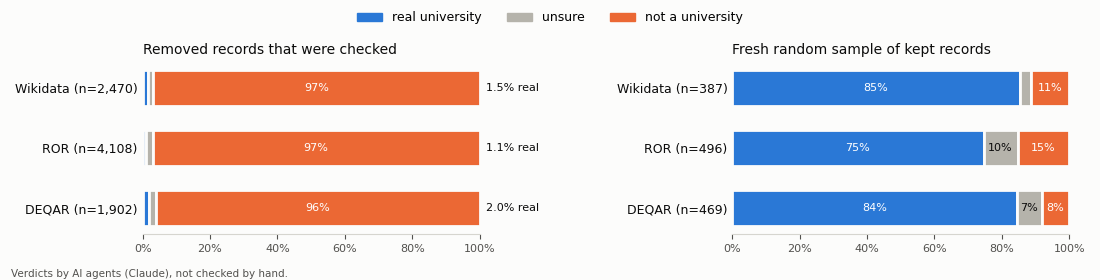

In [4]:
VERDICTS = [("real", "real university", "#2a78d6"), ("unsure", "unsure", "#b5b3ab"),
            ("junk", "not a university", "#eb6834")]
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), facecolor=SURFACE)
titles = {"removed": "Removed records that were checked", "kept": "Fresh random sample of kept records"}
for ax, panel in zip(axes, ["removed", "kept"]):
    ax.set_facecolor(SURFACE)
    sources = list(shares[panel])[::-1]
    for y, source in enumerate(sources):
        n, counts = shares[panel][source]
        left = 0.0
        for key, _, color in VERDICTS:
            width = counts.get(key, 0) / n
            ax.barh(y, width, left=left, height=0.6, color=color, edgecolor=SURFACE, linewidth=2)
            if width >= 0.06:
                ax.text(left + width / 2, y, f"{width:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if key != "unsure" else INK)
            left += width
        if panel == "removed":   # too thin a segment to label inside
            ax.text(1.02, y, f"{counts.get('real', 0) / n:.1%} real", ha="left", va="center",
                    fontsize=8, color=INK, clip_on=False)
    ax.set_yticks(range(len(sources)), [f"{NAMES[s]} (n={shares[panel][s][0]:,})" for s in sources],
                  fontsize=9, color=INK)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.tick_params(axis="x", labelsize=8, colors=MUTED)
    ax.tick_params(axis="y", length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#d6d5cf")
    ax.set_title(titles[panel], fontsize=10, color=INK, loc="left")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for _, _, c in VERDICTS],
           [label for _, label, _ in VERDICTS], loc="upper center", ncol=3, frameon=False, fontsize=9,
           bbox_to_anchor=(0.5, 1.0))
fig.text(0.01, 0.01, "Verdicts by AI agents (Claude), not checked by hand.", fontsize=7.5, color=MUTED)
fig.tight_layout(rect=(0, 0.04, 1, 0.9))
fig.subplots_adjust(wspace=0.75)
plt.show()